0. Import and Path

In [1]:
!pip install scipy matplotlib

  Using cached scipy-1.15.3-cp310-cp310-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (61 kB)
  Using cached matplotlib-3.10.9-cp310-cp310-manylinux2014_x86_64.manylinux_2_17_x86_64.whl.metadata (52 kB)
  Using cached contourpy-1.3.2-cp310-cp310-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (5.5 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached fonttools-4.63.0-cp310-cp310-manylinux2014_x86_64.manylinux_2_17_x86_64.whl.metadata (118 kB)
  Using cached kiwisolver-1.5.0-cp310-cp310-manylinux_2_12_x86_64.manylinux2010_x86_64.whl.metadata (5.1 kB)
  Using cached pillow-12.3.0-cp310-cp310-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (9.1 kB)
  Using cached pyparsing-3.3.2-py3-none-any.whl.metadata (5.8 kB)
Using cached scipy-1.15.3-cp310-cp310-manylinux_2_17_x86_64.manylinux2014_x86_64.whl (37.7 MB)
Using cached matplotlib-3.10.9-cp310-cp310-manylinux2014_x86_64.manylinux_2_17_x86_64.whl (8.8 MB)
Using cached contourpy-1.3.2-c

In [2]:
import pandas as pd
import numpy as np
import random
from scipy.cluster.hierarchy import linkage, fcluster
from scipy.spatial.distance import squareform
import matplotlib.pyplot as plt

RANDOM_SEED = 42
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

SCORE_PATH = "bert_scibert_hac_similarity_scores.csv"
GOLD_CLUSTER_PATH = "clusters.txt"

THRESHOLDS = [0.10, 0.15, 0.20, 0.25, 0.30]
LINKAGE_METHOD = "average"

1. Load gold clusters

In [3]:
# --------------------------------------------------
# Load gold clusters from clusters.txt
# Format: GroupID \t InstanceID|InstanceID|...
# --------------------------------------------------

gold_df = pd.read_csv(
    GOLD_CLUSTER_PATH,
    sep="\t",
    header=None,
    names=["GoldClusterID", "InstanceIDs"],
    dtype=str,
    encoding="utf-8"
)

gold_cluster_dict = {}

for _, row in gold_df.iterrows():
    cluster_id = row["GoldClusterID"]
    instance_ids = str(row["InstanceIDs"]).split("|")
    
    for instance_id in instance_ids:
        gold_cluster_dict[instance_id] = cluster_id

all_instance_ids = sorted(gold_cluster_dict.keys())

print("Number of gold clusters:", gold_df["GoldClusterID"].nunique())
print("Number of instances:", len(all_instance_ids))

Number of gold clusters: 990
Number of instances: 1424


2. Load similarity scores

In [4]:
# --------------------------------------------------
# Load pairwise similarity scores
# SimilarityScore should be match probability
# --------------------------------------------------

scores_df = pd.read_csv(SCORE_PATH, encoding="utf-8-sig")

# Keep only required columns
scores_df = scores_df[
    ["Model", "InstanceID_1", "InstanceID_2", "SimilarityScore"]
].copy()

scores_df["InstanceID_1"] = scores_df["InstanceID_1"].astype(str)
scores_df["InstanceID_2"] = scores_df["InstanceID_2"].astype(str)

print(scores_df.head())
print(scores_df["Model"].value_counts())

  Model InstanceID_1 InstanceID_2  SimilarityScore
0  BERT    100000534    100000935         0.000882
1  BERT    100000334    100000440         0.000564
2  BERT    100001081    100001133         0.000392
3  BERT    100000022    100000639         0.000688
4  BERT    100000056    100000700         0.000821
Model
BERT       3396
SciBERT    3396
Name: count, dtype: int64


3. Cluster-level train/validation/test split

In [5]:
# --------------------------------------------------
# Split gold clusters into train/validation/test clusters
# 70% train, 15% validation, 15% test
# --------------------------------------------------

unique_gold_clusters = gold_df["GoldClusterID"].unique().tolist()
random.shuffle(unique_gold_clusters)

n_clusters = len(unique_gold_clusters)
n_train = int(n_clusters * 0.70)
n_val = int(n_clusters * 0.15)

train_clusters = set(unique_gold_clusters[:n_train])
val_clusters = set(unique_gold_clusters[n_train:n_train + n_val])
test_clusters = set(unique_gold_clusters[n_train + n_val:])

def get_instances_from_clusters(cluster_set):
    # Return instance IDs that belong to selected gold clusters
    return [
        instance_id
        for instance_id, cluster_id in gold_cluster_dict.items()
        if cluster_id in cluster_set
    ]

train_instances = set(get_instances_from_clusters(train_clusters))
val_instances = set(get_instances_from_clusters(val_clusters))
test_instances = set(get_instances_from_clusters(test_clusters))

print("Train clusters:", len(train_clusters), "Train instances:", len(train_instances))
print("Validation clusters:", len(val_clusters), "Validation instances:", len(val_instances))
print("Test clusters:", len(test_clusters), "Test instances:", len(test_instances))

Train clusters: 693 Train instances: 988
Validation clusters: 148 Validation instances: 206
Test clusters: 149 Test instances: 230


4. Similarity matrix builder

In [6]:
# --------------------------------------------------
# Build a full similarity matrix for selected instances
# Missing pairwise scores are treated as 0 similarity
# --------------------------------------------------

def build_similarity_matrix(scores_subset, instance_ids):
    instance_ids = sorted(list(instance_ids))
    id_to_idx = {instance_id: i for i, instance_id in enumerate(instance_ids)}
    
    n = len(instance_ids)
    sim_matrix = np.zeros((n, n), dtype=float)
    
    # Self-similarity is 1
    np.fill_diagonal(sim_matrix, 1.0)
    
    for _, row in scores_subset.iterrows():
        id1 = row["InstanceID_1"]
        id2 = row["InstanceID_2"]
        score = float(row["SimilarityScore"])
        
        if id1 in id_to_idx and id2 in id_to_idx:
            i = id_to_idx[id1]
            j = id_to_idx[id2]
            sim_matrix[i, j] = score
            sim_matrix[j, i] = score
    
    return instance_ids, sim_matrix

5. HAC clustering function

In [7]:
# --------------------------------------------------
# Run HAC clustering using average linkage
# Distance = 1 - SimilarityScore
# --------------------------------------------------

def run_hac_clustering(sim_matrix, instance_ids, threshold, linkage_method="average"):
    # Convert similarity to distance
    distance_matrix = 1.0 - sim_matrix
    
    # Ensure diagonal distance is 0
    np.fill_diagonal(distance_matrix, 0.0)
    
    # Convert square distance matrix to condensed form
    condensed_distance = squareform(distance_matrix, checks=False)
    
    # Run HAC
    Z = linkage(condensed_distance, method=linkage_method)
    
    # Cut dendrogram at the selected distance threshold
    cluster_labels = fcluster(
        Z,
        t=threshold,
        criterion="distance"
    )
    
    pred_cluster_dict = {
        instance_id: str(cluster_label)
        for instance_id, cluster_label in zip(instance_ids, cluster_labels)
    }
    
    return pred_cluster_dict

6. B-cubed evaluation

In [8]:
# --------------------------------------------------
# Compute B-cubed Precision, Recall, and F1
# --------------------------------------------------

def bcubed_evaluation(gold_dict, pred_dict, instance_ids):
    precisions = []
    recalls = []
    
    for instance_id in instance_ids:
        gold_cluster = {
            x for x in instance_ids
            if gold_dict[x] == gold_dict[instance_id]
        }
        
        pred_cluster = {
            x for x in instance_ids
            if pred_dict[x] == pred_dict[instance_id]
        }
        
        intersection = gold_cluster & pred_cluster
        
        precision_i = len(intersection) / len(pred_cluster) if len(pred_cluster) > 0 else 0
        recall_i = len(intersection) / len(gold_cluster) if len(gold_cluster) > 0 else 0
        
        precisions.append(precision_i)
        recalls.append(recall_i)
    
    precision = np.mean(precisions)
    recall = np.mean(recalls)
    
    if precision + recall == 0:
        f1 = 0
    else:
        f1 = 2 * precision * recall / (precision + recall)
    
    return precision, recall, f1

7. Threshold sweep on validation set

In [9]:
# --------------------------------------------------
# Tune threshold on validation set only
# --------------------------------------------------

validation_results = []

for model_name in scores_df["Model"].unique():
    model_scores = scores_df[scores_df["Model"] == model_name].copy()
    
    val_scores = model_scores[
        model_scores["InstanceID_1"].isin(val_instances)
        & model_scores["InstanceID_2"].isin(val_instances)
    ].copy()
    
    val_instance_ids, val_sim_matrix = build_similarity_matrix(
        val_scores,
        val_instances
    )
    
    for threshold in THRESHOLDS:
        pred_val_clusters = run_hac_clustering(
            sim_matrix=val_sim_matrix,
            instance_ids=val_instance_ids,
            threshold=threshold,
            linkage_method=LINKAGE_METHOD
        )
        
        p, r, f1 = bcubed_evaluation(
            gold_dict=gold_cluster_dict,
            pred_dict=pred_val_clusters,
            instance_ids=val_instance_ids
        )
        
        validation_results.append({
            "Model": model_name,
            "Split": "validation",
            "Threshold": threshold,
            "Linkage": LINKAGE_METHOD,
            "B3_Precision": p,
            "B3_Recall": r,
            "B3_F1": f1,
            "NumInstances": len(val_instance_ids),
            "NumGoldClusters": len(val_clusters)
        })

validation_results_df = pd.DataFrame(validation_results)

validation_results_df.to_csv(
    "hac_validation_threshold_results.csv",
    index=False,
    encoding="utf-8-sig"
)

print(validation_results_df)

     Model       Split  Threshold  Linkage  B3_Precision  B3_Recall     B3_F1  \
0     BERT  validation       0.10  average           1.0   0.985437  0.992665   
1     BERT  validation       0.15  average           1.0   0.985437  0.992665   
2     BERT  validation       0.20  average           1.0   0.985437  0.992665   
3     BERT  validation       0.25  average           1.0   0.990291  0.995122   
4     BERT  validation       0.30  average           1.0   0.990291  0.995122   
5  SciBERT  validation       0.10  average           1.0   0.980583  0.990196   
6  SciBERT  validation       0.15  average           1.0   0.980583  0.990196   
7  SciBERT  validation       0.20  average           1.0   0.980583  0.990196   
8  SciBERT  validation       0.25  average           1.0   0.980583  0.990196   
9  SciBERT  validation       0.30  average           1.0   0.980583  0.990196   

   NumInstances  NumGoldClusters  
0           206              148  
1           206              148  
2  

8. Select best threshold from validation

In [10]:
# --------------------------------------------------
# Select the best threshold per model based on validation B-cubed F1
# --------------------------------------------------

best_thresholds_df = (
    validation_results_df
    .sort_values(["Model", "B3_F1"], ascending=[True, False])
    .groupby("Model")
    .head(1)
    .reset_index(drop=True)
)

best_thresholds_df.to_csv(
    "hac_best_thresholds_from_validation.csv",
    index=False,
    encoding="utf-8-sig"
)

print(best_thresholds_df)

     Model       Split  Threshold  Linkage  B3_Precision  B3_Recall     B3_F1  \
0     BERT  validation       0.25  average           1.0   0.990291  0.995122   
1  SciBERT  validation       0.10  average           1.0   0.980583  0.990196   

   NumInstances  NumGoldClusters  
0           206              148  
1           206              148  


9. Final test evaluation once

In [11]:
# --------------------------------------------------
# Apply the selected threshold to the test set once
# --------------------------------------------------

test_results = []
test_cluster_outputs = []

for _, best_row in best_thresholds_df.iterrows():
    model_name = best_row["Model"]
    best_threshold = best_row["Threshold"]
    
    model_scores = scores_df[scores_df["Model"] == model_name].copy()
    
    test_scores = model_scores[
        model_scores["InstanceID_1"].isin(test_instances)
        & model_scores["InstanceID_2"].isin(test_instances)
    ].copy()
    
    test_instance_ids, test_sim_matrix = build_similarity_matrix(
        test_scores,
        test_instances
    )
    
    pred_test_clusters = run_hac_clustering(
        sim_matrix=test_sim_matrix,
        instance_ids=test_instance_ids,
        threshold=best_threshold,
        linkage_method=LINKAGE_METHOD
    )
    
    p, r, f1 = bcubed_evaluation(
        gold_dict=gold_cluster_dict,
        pred_dict=pred_test_clusters,
        instance_ids=test_instance_ids
    )
    
    test_results.append({
        "Model": model_name,
        "Split": "test",
        "SelectedThreshold": best_threshold,
        "Linkage": LINKAGE_METHOD,
        "B3_Precision": p,
        "B3_Recall": r,
        "B3_F1": f1,
        "NumInstances": len(test_instance_ids),
        "NumGoldClusters": len(test_clusters)
    })
    
    for instance_id, pred_cluster_id in pred_test_clusters.items():
        test_cluster_outputs.append({
            "Model": model_name,
            "InstanceID": instance_id,
            "GoldClusterID": gold_cluster_dict[instance_id],
            "PredClusterID": pred_cluster_id,
            "SelectedThreshold": best_threshold
        })

test_results_df = pd.DataFrame(test_results)
test_cluster_outputs_df = pd.DataFrame(test_cluster_outputs)

test_results_df.to_csv(
    "hac_final_test_results.csv",
    index=False,
    encoding="utf-8-sig"
)

test_cluster_outputs_df.to_csv(
    "hac_test_predicted_clusters.csv",
    index=False,
    encoding="utf-8-sig"
)

print(test_results_df)

     Model Split  SelectedThreshold  Linkage  B3_Precision  B3_Recall  \
0     BERT  test               0.25  average           1.0   0.969565   
1  SciBERT  test               0.10  average           1.0   0.954658   

      B3_F1  NumInstances  NumGoldClusters  
0  0.984547           230              149  
1  0.976803           230              149  


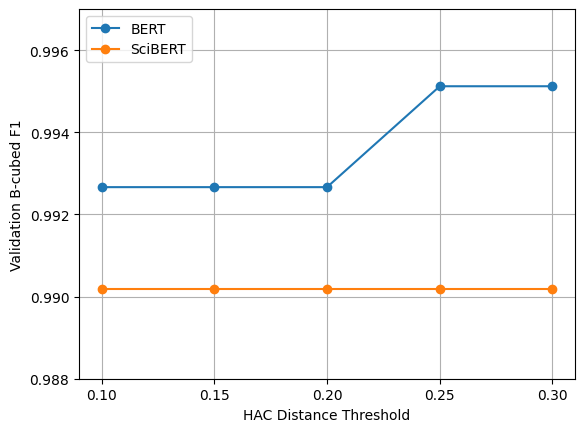

In [18]:
# --------------------------------------------------
# Plot validation B-cubed F1 by threshold
# --------------------------------------------------

plt.figure()

for model_name in validation_results_df["Model"].unique():
    temp = validation_results_df[
        validation_results_df["Model"] == model_name
    ].sort_values("Threshold")
    
    plt.plot(
        temp["Threshold"],
        temp["B3_F1"],
        marker="o",
        label=model_name
    )

plt.xlabel("HAC Distance Threshold")
plt.ylabel("Validation B-cubed F1")
# plt.title("HAC Threshold Tuning on Validation Set")

# Set the x-axis ticks to the five tested thresholds
plt.xticks(
    [0.10, 0.15, 0.20, 0.25, 0.30],
    ["0.10", "0.15", "0.20", "0.25", "0.30"]
)

# Set the y-axis range
plt.ylim(0.988, 0.997)

# Place the legend in the upper-left corner
plt.legend(loc="upper left")

plt.grid(True)
plt.show()

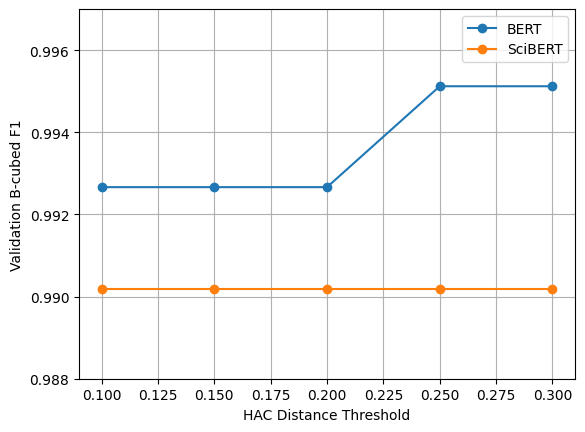

In [17]:
# --------------------------------------------------
# Save visualization
# --------------------------------------------------

plt.figure()

for model_name in validation_results_df["Model"].unique():
    temp = validation_results_df[
        validation_results_df["Model"] == model_name
    ].sort_values("Threshold")
    
    plt.plot(
        temp["Threshold"],
        temp["B3_F1"],
        marker="o",
        label=model_name
    )

plt.xlabel("HAC Distance Threshold")
plt.ylabel("Validation B-cubed F1")
# plt.title("HAC Threshold Tuning on Validation Set")

# Set the y-axis range
plt.ylim(0.988, 0.997)

plt.legend()
plt.grid(True)

plt.savefig(
    "hac_validation_threshold_tuning.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()